# Border-crossing activity and the El Paso–Juárez regional economy

**Question.** How does border-crossing activity relate to regional economic activity across
El Paso and Ciudad Juárez, and how does that link respond to crossing friction?

| Test | Result |
|---|---|
| **Composite border-crossing activity vs. El Paso employment** (YoY growth) | **r ≈ +0.53** (retail employment: +0.60) |
| Raw levels correlation, crossings vs. El Paso employment | r ≈ −0.54 — spurious (opposite 25-year trends) |
| Engle–Granger cointegration (levels) | none — no stable long-run tie |
| Granger causality | El Paso activity → crossings (crossings are demand-driven) |
| Commerce co-movement — crossings vs. El Paso retail *sales* (quarterly, YoY) | r ≈ +0.66 |
| **2019 CBP officer reassignment** | personal vehicles **−9.9%** (p=0.002), pedestrians **+28%**, **trucks +1% (n.s.)** |
| **COVID land-border ban** | personal vehicles **−39%**, pedestrians **−54%**, **trucks −1% (n.s.)**, El Paso retail employment −5.9% (p=0.005) |

**Read.** Border-crossing activity and the regional economy move together (r ≈ 0.5–0.66 in
growth rates). Friction shocks hit the *consumer/commuter* channels hard — but **freight is
friction-immune**: the Juárez maquiladora supply chain kept running through both the 2019
slowdown and the COVID ban.

Data: BTS border crossings (El Paso / Ysleta / Tornillo — personal vehicles, pedestrians, trucks,
bus passengers), FRED (El Paso MSA employment & retail employment, MXN/USD, US retail, CPI), Texas
Comptroller sales-tax allocations (monthly) and taxable sales by industry (quarterly). 2000–2026.

All fetching and modeling lives in [`analyze.py`](analyze.py); this notebook narrates it.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

import analyze  # fetchers + estimators, cached under data/raw/

## 1 · Build the monthly panel

`build_panel()` pulls the three sources (cached to `data/raw/`), aligns them to month-start, adds log transforms, a linear trend, and the two event dummies, and writes `output/panel_elpaso_juarez.csv`.

In [2]:
p = analyze.build_panel()
print(p.index.min().date(), "→", p.index.max().date(), "|", len(p), "months")
p[["crossings", "pedestrians", "elpaso_emp", "elpaso_retail_emp", "sales_tax", "mxn_usd"]].describe().round(2)

fetching BTS ...
fetching FRED ...
fetching Comptroller ...
2000-01-01 → 2026-07-01 | 319 months


,crossings,pedestrians,elpaso_emp,elpaso_retail_emp,sales_tax,mxn_usd
count,319.00,319.00,317.00,319.00,162.00,319.00
mean,1.06,0.57,320.66,36.29,8.79,14.73
std,0.22,0.14,46.34,3.02,2.28,4.00
min,0.36,0.10,254.51,30.10,5.41,9.06
25%,0.92,0.50,275.11,33.50,6.72,10.99
50%,1.04,0.59,318.93,36.70,8.10,13.23
75%,1.19,0.66,358.14,39.10,10.69,18.77
max,1.76,1.24,406.09,41.90,16.06,24.18


## 2 · The raw picture

Crossings fall for 25 years (trusted-traveler lanes, the 2008 recession, tighter ID rules); El Paso employment climbs. Whatever links them is not visible in levels.

Pearson r (crossings, El Paso employment): -0.541


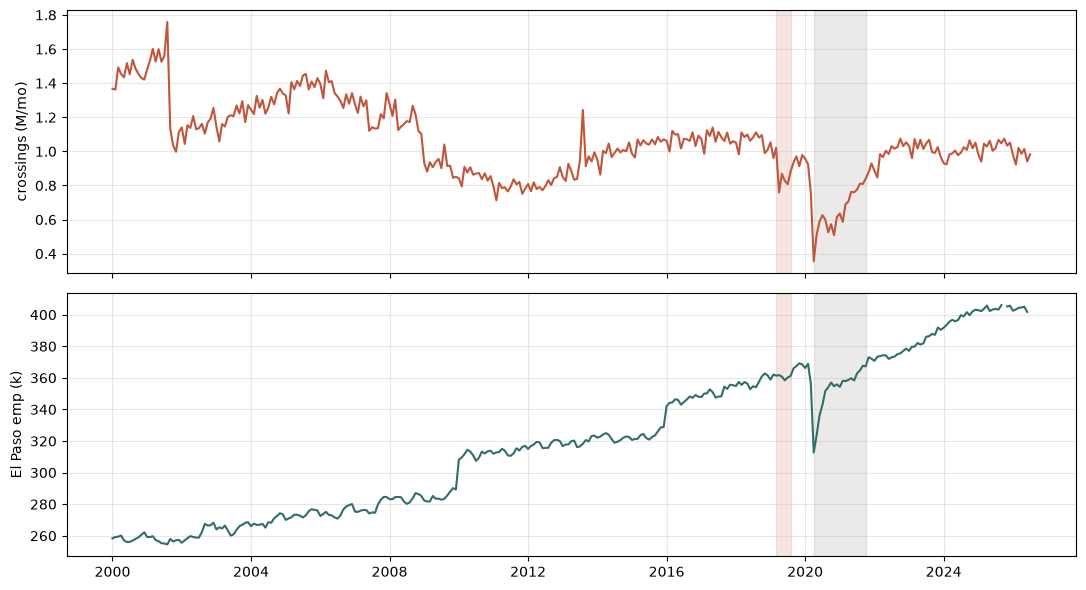

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(p.index, p["crossings"], color="#c0563b"); ax[0].set_ylabel("crossings (M/mo)")
ax[1].plot(p.index, p["elpaso_emp"], color="#2f6f6a"); ax[1].set_ylabel("El Paso emp (k)")
for a in ax:
    a.axvspan(pd.Timestamp("2019-03"), pd.Timestamp("2019-08"), color="#c0563b", alpha=.15)
    a.axvspan(pd.Timestamp("2020-04"), pd.Timestamp("2021-10"), color="#5c574d", alpha=.12)
    a.grid(alpha=.3)
plt.tight_layout()

print("Pearson r (crossings, El Paso employment):",
      round(p[["crossings", "elpaso_emp"]].corr().iloc[0, 1], 3))

## 3 · Stationarity & cointegration

All series are I(1). Engle–Granger asks whether a linear combination is stationary — i.e. whether the two economies track a common path. They do not.

In [4]:
display(analyze.stationarity(p))

for y in ["l_elpaso_emp", "l_elpaso_retail_emp"]:
    print(analyze.engle_granger(p, y, "l_crossings"))

,series,adf_p_level,adf_p_diff
0,l_crossings,0.079,0.000
1,l_elpaso_emp,0.928,0.000
2,l_elpaso_retail_emp,0.641,0.000
3,l_sales_tax,0.979,0.001
4,mxn_usd,0.576,0.000


{'pair': 'l_elpaso_emp ~ l_crossings', 'coint_p': 0.8961, 'resid_adf_p': 0.7567, 'long_run_beta': -0.337, 'cointegrated': False}
{'pair': 'l_elpaso_retail_emp ~ l_crossings', 'coint_p': 0.6417, 'resid_adf_p': 0.3934, 'long_run_beta': -0.139, 'cointegrated': False}


## 4 · Granger causality (differenced logs)

Which way does prediction run? El Paso activity leads crossings, not the reverse — people cross *because* there is economic activity, so crossing volume is mostly a demand signal.

In [5]:
print("crossings → El Paso emp  (p by lag):", analyze.granger(p, "l_elpaso_emp", "l_crossings"))
print("El Paso emp → crossings  (p by lag):", analyze.granger(p, "l_crossings", "l_elpaso_emp"))

crossings → El Paso emp  (p by lag): {1: np.float64(0.1165), 2: np.float64(0.3138), 3: np.float64(0.065), 4: np.float64(0.0567)}
El Paso emp → crossings  (p by lag): {1: np.float64(0.0211), 2: np.float64(0.0002), 3: np.float64(0.0019), 4: np.float64(0.0039)}


## 5 · Event study — the 2019 CBP officer reassignment

Spring 2019: CBP moved hundreds of officers off the El Paso ports of entry; wait times spiked for months, unrelated to the local business cycle. Model:

$$\log y_t = \beta\,\text{Slowdown2019}_t + \gamma\,\text{CovidBan}_t + \text{month FE} + \delta\,t + \theta_1 \log \text{peso}_t + \theta_2 \log \text{USretail}_t + \varepsilon_t$$

with HAC (Newey–West, 6-lag) standard errors.

In [6]:
for dep in ["l_crossings", "l_pedestrians", "l_elpaso_emp", "l_elpaso_retail_emp", "l_sales_tax"]:
    r = analyze.event_study(p, dep)
    s = r["slowdown_2019"]
    print(f"{dep:20s}  2019: {s['pct']:+6.1f}%  (β={s['beta']:+.3f}, SE {s['se']:.3f}, p={s['p']:.3f}, n={r['n']})")

l_crossings           2019:   -9.9%  (β=-0.105, SE 0.034, p=0.002, n=319)


l_pedestrians         2019:  +28.0%  (β=+0.246, SE 0.042, p=0.000, n=319)
l_elpaso_emp          2019:   +0.9%  (β=+0.009, SE 0.006, p=0.181, n=317)
l_elpaso_retail_emp   2019:   -1.7%  (β=-0.017, SE 0.011, p=0.118, n=319)
l_sales_tax           2019:   +1.5%  (β=+0.015, SE 0.009, p=0.111, n=162)


In [7]:
# full regression table for the headline outcome
d = p.dropna(subset=["l_crossings", "l_mxn_usd", "l_us_retail"]).copy()
X = pd.DataFrame(index=d.index)
X["slowdown_2019"] = d["slowdown_2019"]; X["covid_ban"] = d["covid_ban"]
X["l_mxn_usd"] = d["l_mxn_usd"]; X["l_us_retail"] = d["l_us_retail"]; X["t"] = d["t"]
for m in range(2, 13):
    X[f"m{m}"] = (d["month"] == m).astype(float)
fit = sm.OLS(d["l_crossings"], sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(fit.summary().tables[1])

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -25.4133      3.725     -6.822      0.000     -32.714     -18.112
slowdown_2019    -0.1046      0.034     -3.095      0.002      -0.171      -0.038
covid_ban        -0.5006      0.065     -7.694      0.000      -0.628      -0.373
l_mxn_usd         0.6107      0.170      3.586      0.000       0.277       0.944
l_us_retail       1.9646      0.277      7.100      0.000       1.422       2.507
t                -0.0087      0.001     -7.297      0.000      -0.011      -0.006
m2               -0.0491      0.012     -4.093      0.000      -0.073      -0.026
m3                0.0422      0.018      2.282      0.023       0.006       0.078
m4                0.0092      0.022      0.417      0.677      -0.034       0.052
m5                0.0431      0.023      1.889      0.059      -0.002       0.088
m6              

### Robustness — alternative windows

In [8]:
for w in [("2019-03-01", "2019-08-31"), ("2019-04-01", "2019-07-31"), ("2019-03-01", "2019-06-30")]:
    s = analyze.event_study(p, "l_crossings", window=w)["slowdown_2019"]
    print(f"{w[0][:7]}..{w[1][:7]}   {s['pct']:+.1f}%   (p={s['p']:.3f})")

2019-03..2019-08   -9.9%   (p=0.002)
2019-04..2019-07   -13.0%   (p=0.000)
2019-03..2019-06   -7.7%   (p=0.018)


## 6 · COVID land-border ban — the dose–response check

The 2019 slowdown was months long and moderate. The COVID non-essential-travel ban was 19 months and severe. If friction matters for the *economy*, the bigger dose should show a bigger response — and it does.

In [9]:
for dep in ["l_crossings", "l_elpaso_emp", "l_elpaso_retail_emp"]:
    c = analyze.event_study(p, dep)["covid_ban"]
    print(f"{dep:20s}  COVID: {c['pct']:+7.1f}%  (p={c['p']:.3f})")

l_crossings           COVID:   -39.4%  (p=0.000)
l_elpaso_emp          COVID:    -4.7%  (p=0.000)
l_elpaso_retail_emp   COVID:    -5.9%  (p=0.005)


## 7 · Commerce — does El Paso retail spending track the crossings?

The intuitive channel: Ciudad Juárez residents cross, shop in El Paso, and it lands in taxable
sales. Quarterly Texas Comptroller data (`7z4d-yf2c`, El Paso, 2016+), by industry.

- In **levels**, crossings and retail sales barely correlate — the same trend problem.
- In **year-over-year growth**, they move together (r ≈ 0.66) — the binational linkage the levels
  correlation hides.
- But no single friction shock cleanly dents *total* retail: 2019 left it flat; during COVID,
  general retail held up (stimulus offset the missing cross-border shoppers) while
  **accommodation & food fell ~14%**. Cross-border shoppers are a real but minority slice of El
  Paso retail, so the link shows up as co-movement, not as a levels response to one event.

quarterly taxable sales, 2016-01-01 .. 2026-01-01  (n=41)

corr(crossings, retail sales)  levels : +0.10
corr(crossings, retail sales)  YoY %  : +0.66

l_sales_retail    2019:  -0.7% (p=0.39)   COVID:   -3.3% (p=0.19)
l_sales_accom     2019:  +3.9% (p=0.00)   COVID:  -14.1% (p=0.00)
l_sales_all       2019:  +0.5% (p=0.35)   COVID:   -7.7% (p=0.00)


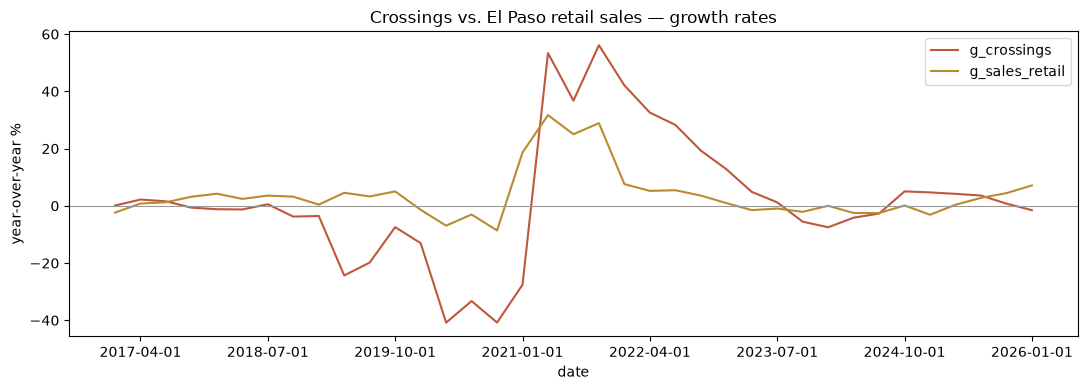

In [10]:
com = analyze.commerce(p)
print(f"quarterly taxable sales, {com['start']} .. {com['end']}  (n={com['n']})\n")
print(f"corr(crossings, retail sales)  levels : {com['corr_levels']:+.2f}")
print(f"corr(crossings, retail sales)  YoY %  : {com['corr_yoy_growth']:+.2f}\n")
for k in ["l_sales_retail", "l_sales_accom", "l_sales_all"]:
    e = com[k]
    print(f"{k:16s}  2019: {e['slowdown_2019_pct']:+5.1f}% (p={e['slowdown_2019_p']:.2f})"
          f"   COVID: {e['covid_pct']:+6.1f}% (p={e['covid_p']:.2f})")

g = pd.DataFrame(com["_frame"]).set_index("date")
ax = g[["g_crossings", "g_sales_retail"]].plot(figsize=(11, 4), color=["#c0563b", "#b98b2e"])
ax.axhline(0, color="#999", lw=.8); ax.set_ylabel("year-over-year %"); ax.set_title("Crossings vs. El Paso retail sales — growth rates")
plt.tight_layout()

## 8 · Border-crossing activity by channel vs. regional economic activity

Crossings aren't one thing. Split BTS volumes into **personal vehicles** (shopping / commuting),
**pedestrians**, **trucks** (the Juárez maquiladora supply chain) and **bus passengers**, plus a
composite index (first principal component of the four). Measure each channel's YoY-growth
correlation with El Paso employment and retail, and its response to the two friction shocks.

Payoff: **freight is friction-immune** — truck crossings show no measurable effect from the 2019
slowdown or even the COVID ban, while consumer/commuter channels swing 10–50%. Border friction
taxes cross-border *consumers and workers*, not the industrial integration between the two cities.

,corr_emp_yoy,corr_retail_yoy,e2019_pct,e2019_p,ecovid_pct,ecovid_p
label,,,,,,
Personal vehicles,0.435,0.617,-9.93,0.002,-39.38,0.00
Pedestrians,0.349,0.361,27.96,0.000,-54.02,0.00
Trucks (freight),0.359,0.347,1.07,0.544,-1.32,0.75
Bus passengers,0.283,0.363,38.80,0.000,-52.37,0.00
Composite index,0.529,0.596,NaN,NaN,NaN,NaN



composite border-crossing activity vs El Paso employment (YoY growth): r = +0.53


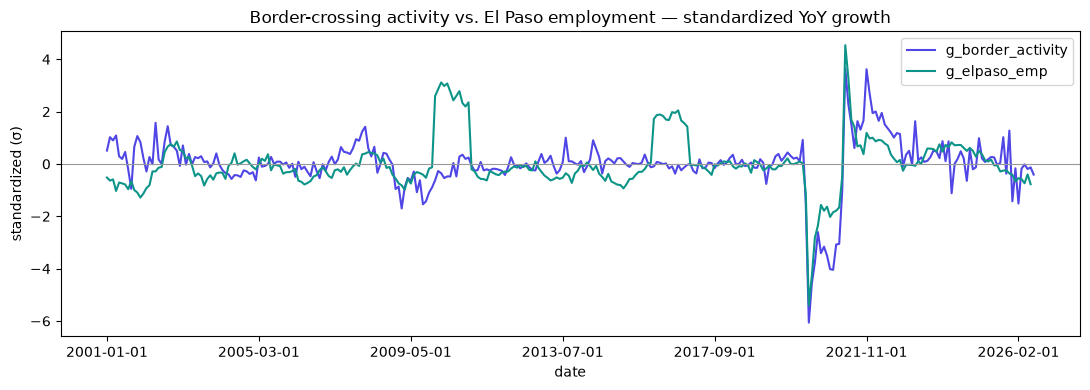

In [11]:
ch = analyze.channels(p)
tbl = pd.DataFrame(ch["rows"]).set_index("label")[
    ["corr_emp_yoy", "corr_retail_yoy", "e2019_pct", "e2019_p", "ecovid_pct", "ecovid_p"]
]
display(tbl.round(3))
print(f"\ncomposite border-crossing activity vs El Paso employment (YoY growth): r = {ch['composite_corr_emp_yoy']:+.2f}")

f = pd.DataFrame(ch["_frame"]).set_index("date")
z = (f[["g_border_activity", "g_elpaso_emp"]] - f[["g_border_activity", "g_elpaso_emp"]].mean()) / f[["g_border_activity", "g_elpaso_emp"]].std()
ax = z.plot(figsize=(11, 4), color=["#4f46e5", "#0d9488"])
ax.axhline(0, color="#999", lw=.8); ax.set_ylabel("standardized (σ)")
ax.set_title("Border-crossing activity vs. El Paso employment — standardized YoY growth")
plt.tight_layout()

## 9 · Export for the front end

`analyze.main()` runs everything above and writes `../mockup/src/data/{panel,findings,commerce,channels}.json`
and the figures in `../docs/`. The React dashboard in `../mockup` picks them up automatically.

In [12]:
analyze.main()

fetching BTS ...
fetching FRED ...
fetching Comptroller ...

panel: 2000-01-01 .. 2026-07-01  (319 months)

             series  adf_p_level  adf_p_diff
        l_crossings        0.079       0.000
       l_elpaso_emp        0.928       0.000
l_elpaso_retail_emp        0.641       0.000
        l_sales_tax        0.979       0.001
            mxn_usd        0.576       0.000 

  Engle-Granger l_elpaso_emp ~ l_crossings          coint p=0.896  resid ADF p=0.757  beta=-0.337  -> no
  Engle-Granger l_elpaso_retail_emp ~ l_crossings   coint p=0.642  resid ADF p=0.393  beta=-0.139  -> no

  Granger crossings -> El Paso emp : p by lag {1: np.float64(0.1165), 2: np.float64(0.3138), 3: np.float64(0.065), 4: np.float64(0.0567)}
  Granger El Paso emp -> crossings : p by lag {1: np.float64(0.0211), 2: np.float64(0.0002), 3: np.float64(0.0019), 4: np.float64(0.0039)}



  2019 CBP officer reassignment (Mar–Aug 2019)          COVID land-border ban (Apr'20–Oct'21)
  l_crossings             -9.9%  (p=0.002)            -39.4%  (p=0.000)
  l_pedestrians          +28.0%  (p=0.000)            -54.0%  (p=0.000)
  l_elpaso_emp            +0.9%  (p=0.181)             -4.7%  (p=0.000)
  l_elpaso_retail_emp     -1.7%  (p=0.118)             -5.9%  (p=0.005)
  l_sales_tax             +1.5%  (p=0.111)             +0.6%  (p=0.596)

  crossings effect by window:
    2019-03..2019-08  -9.9%  (p=0.002)
    2019-04..2019-07  -13.0%  (p=0.000)
    2019-03..2019-06  -7.7%  (p=0.018)

  El Paso sales-tax vs. seasonal counterfactual over the window: $+0.7M  (baseline ~$8.1M/mo, n=6)

  BORDER CROSSING ACTIVITY vs. REGIONAL ECONOMY (YoY growth correlation + shock effects)
  channel            corr w/ El Paso emp corr w/ retail emp   2019 shock      COVID shock
  Personal vehicles               0.435              0.617   -10% (p=0.00)    -39% (p=0.00)
  Pedestrians            

wrote figures to /Users/sofiadeharo/border-wait-times/docs

wrote /Users/sofiadeharo/border-wait-times/mockup/src/data/findings.json and /Users/sofiadeharo/border-wait-times/mockup/src/data/panel.json
{
  "generated_at": "2026-09-01T04:22:32.816030+00:00",
  "sample": {
    "start": "2000-01-01",
    "end": "2026-07-01",
    "n": 319
  },
  "headline": {
    "stat": "-10%",
    "label": "drop in El Paso personal-vehicle crossings during the 2019 CBP officer reassignment (Mar\u2013Aug), net of seasonality, trend, the peso and US retail sales \u2014 while pedestrian crossings rose +28% as travelers switched modes"
  },
  "pearson_crossings_activity": -0.541,
  "cointegration": {
    "pair": "El Paso crossings ~ retail-trade employment (log levels, 2000\u20132026)",
    "resid_adf_p": 0.3934,
    "long_run_beta": -0.139,
    "cointegrated": false
  },
  "granger": {
    "crossings_to_activity_p": 0.0567,
    "activity_to_crossings_p": 0.0002
  },
  "event_2019": {
    "window": "2019-03 .